# DS2002 · Midterm Clinic Analysis and Charts

**Studio — 2026-10-28 · Fall 2026**  
**Class time:** 45 minutes

---

## Clinic — analysis and charts

Working session on your own project. The patterns below are the four analytical moves Questions 1 through 4 need; adapt each one to your cleaned data.

By the end of the hour you should have at least two charts you would be willing to put in the presentation on Monday.

### Pattern 1 — products moving together before landfall

One line per product, landfall marked. This is the Q1 chart, and it is the one that carries your presentation.

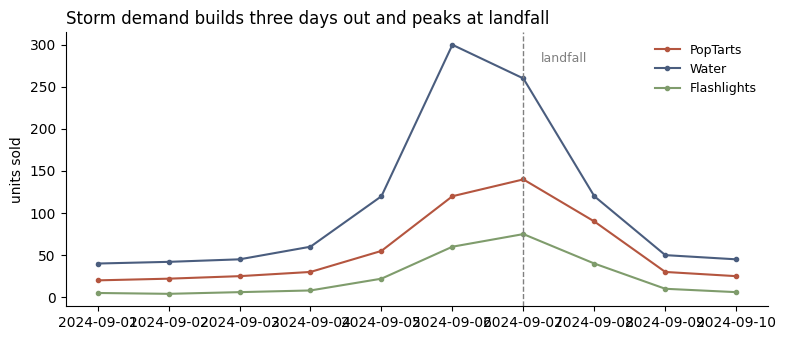

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

daily = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=10),
    'PopTarts': [20, 22, 25, 30, 55, 120, 140, 90, 30, 25],
    'Water': [40, 42, 45, 60, 120, 300, 260, 120, 50, 45],
    'Flashlights': [5, 4, 6, 8, 22, 60, 75, 40, 10, 6],
}).set_index('date')
landfall = pd.Timestamp('2024-09-07')

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(daily.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(daily.index, daily[col], marker='o', ms=3, color=color, label=col)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(landfall + pd.Timedelta(hours=6), 280),
            fontsize=9, color='gray')
ax.set_title('Storm demand builds three days out and peaks at landfall',
             loc='left', fontsize=12)
ax.set_ylabel('units sold')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** rebuild that with your own cleaned categories and your own landfall date. Title it with what your data actually shows — if your surge peaks a day early, say that.

In [5]:
sales = pd.read_csv(
    "ds2002-fa26/notebooks/walmart-hurricane-project/data/walmart_transactions.csv"
)

q1 = sales.copy()

q1["timestamp"] = pd.to_datetime(q1["timestamp"], errors="coerce")
q1["date"] = q1["timestamp"].dt.normalize()
q1["quantity"] = pd.to_numeric(q1["quantity"], errors="coerce")

print(q1["date"].min(), q1["date"].max())
print(q1["category"].value_counts())

2024-09-01 00:00:00 2024-09-30 00:00:00
category
EMERGENCY                1823
Emergency Supplies       1819
emergency                1789
Emergency                1764
Groceries                 859
electronics               857
Electronics               845
Grocery                   837
ELECTRONICS               824
grocery                   813
GROCERY                   806
Entertainment             649
Games & Entertainment     647
entertainment             641
HOUSEHOLD                 604
ENTERTAINMENT             604
Household                 590
household                 586
Household Essentials      571
baby                      550
breakfast                 535
Breakfast                 524
Baby                      522
BABY                      520
BREAKFAST                 510
Baby Products             498
Breakfast Foods           494
Alcohol                   440
ALCOHOL                   426
Alcoholic Beverages       403
Snacks                    339
snacks               

In [6]:
category_map = {
    "emergency": "Emergency Supplies",
    "emergency supplies": "Emergency Supplies",
    "grocery": "Groceries",
    "groceries": "Groceries",
    "electronics": "Electronics",
    "entertainment": "Entertainment",
    "games & entertainment": "Entertainment",
    "household": "Household Essentials",
    "household essentials": "Household Essentials",
    "baby": "Baby Products",
    "baby products": "Baby Products",
    "breakfast": "Breakfast Foods",
    "breakfast foods": "Breakfast Foods",
    "alcohol": "Alcoholic Beverages",
    "alcoholic beverages": "Alcoholic Beverages",
    "snacks": "Snacks",
    "health": "Health & Wellness",
    "health & wellness": "Health & Wellness"
}

q1["category_clean"] = (
    q1["category"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map(category_map)
)

print(q1["category_clean"].value_counts())

category_clean
Emergency Supplies      7195
Groceries               3315
Entertainment           2541
Electronics             2526
Household Essentials    2351
Baby Products           2090
Breakfast Foods         2063
Alcoholic Beverages     1269
Health & Wellness       1231
Snacks                   981
Name: count, dtype: int64


In [8]:
daily_q1 = (
    q1.groupby(["date", "category_clean"])["quantity"]
    .sum()
    .unstack(fill_value=0)
)

daily_q1
daily_q1.idxmax()

,0
category_clean,
Alcoholic Beverages,2024-09-14
Baby Products,2024-09-14
Breakfast Foods,2024-09-14
Electronics,2024-09-13
Emergency Supplies,2024-09-13
Entertainment,2024-09-14
Groceries,2024-09-13
Health & Wellness,2024-09-15
Household Essentials,2024-09-11


In [9]:
!grep -Rni "landfall" ds2002-fa26/notebooks/walmart-hurricane-project

ds2002-fa26/notebooks/walmart-hurricane-project/notebooks/scratch/noor_weather_api-2.ipynb:170:        "Hurricane Helene made landfall on the Florida Big Bend late on **September 26, 2024**. That is the landfall date for this project. The sales data is built around it, and the real weather you pull from the API lines up with it.\n",
ds2002-fa26/notebooks/walmart-hurricane-project/notebooks/scratch/noor_weather_api-2.ipynb:179:        "| Sept 24–25 | about 2,000 | The peak, the two days before landfall |\n",
ds2002-fa26/notebooks/walmart-hurricane-project/notebooks/scratch/noor_weather_api-2.ipynb:180:        "| Sept 26 | about 1,140 | Landfall. Orders fall back to about half the peak. |\n",
ds2002-fa26/notebooks/walmart-hurricane-project/notebooks/scratch/noor_weather_api-2.ipynb:184:        "Use Sept 26 as landfall for the windows in Question 1 and the lag in Question 3.\n",
ds2002-fa26/notebooks/walmart-hurricane-project/notebooks/scratch/noor_weather_api-2.ipynb:394:        "LANDFAL

In [10]:
landfall = pd.Timestamp("2024-09-26")

baseline_start = pd.Timestamp("2024-09-08")
baseline_end = pd.Timestamp("2024-09-15")

surge_start = pd.Timestamp("2024-09-23")
surge_end = pd.Timestamp("2024-09-25")

baseline_avg = daily_q1.loc[baseline_start:baseline_end].mean()
surge_avg = daily_q1.loc[surge_start:surge_end].mean()

surge_multiple = (surge_avg / baseline_avg).sort_values(ascending=False)

print(surge_multiple.round(2))

category_clean
Baby Products           0.80
Groceries               0.73
Snacks                  0.57
Health & Wellness       0.47
Household Essentials    0.42
Alcoholic Beverages     0.39
Electronics             0.38
Emergency Supplies      0.38
Entertainment           0.30
Breakfast Foods         0.20
dtype: float64


In [11]:
daily_q1.sum(axis=1)

,0
date,
2024-09-01,122
2024-09-02,101
2024-09-03,120
2024-09-04,99
2024-09-05,139
2024-09-06,158
2024-09-07,142
2024-09-08,126
2024-09-09,134


In [12]:
landfall = pd.Timestamp("2024-09-26")

baseline_start = pd.Timestamp("2024-09-12")
baseline_end = pd.Timestamp("2024-09-18")

surge_start = pd.Timestamp("2024-09-19")
surge_end = pd.Timestamp("2024-09-25")

baseline_avg = daily_q1.loc[baseline_start:baseline_end].mean()
surge_avg = daily_q1.loc[surge_start:surge_end].mean()

surge_multiple = surge_avg / baseline_avg
percent_increase = (surge_multiple - 1) * 100

q1_results = pd.DataFrame({
    "baseline_avg": baseline_avg,
    "pre_landfall_avg": surge_avg,
    "surge_multiple": surge_multiple,
    "percent_change": percent_increase
}).sort_values("percent_change", ascending=False)

q1_results.round(2)

,baseline_avg,pre_landfall_avg,surge_multiple,percent_change
category_clean,,,,
Snacks,8.43,6.00,0.71,-28.81
Groceries,31.43,22.00,0.70,-30.00
Baby Products,14.29,9.14,0.64,-36.00
Electronics,15.00,7.43,0.50,-50.48
Entertainment,20.29,9.71,0.48,-52.11
Health & Wellness,9.29,4.00,0.43,-56.92
Household Essentials,14.86,6.29,0.42,-57.69
Emergency Supplies,93.86,33.57,0.36,-64.23
Alcoholic Beverages,14.86,5.14,0.35,-65.38


In [13]:
baseline_start = pd.Timestamp("2024-09-01")
baseline_end = pd.Timestamp("2024-09-09")

surge_start = pd.Timestamp("2024-09-10")
surge_end = pd.Timestamp("2024-09-15")

baseline_avg = daily_q1.loc[baseline_start:baseline_end].mean()
surge_avg = daily_q1.loc[surge_start:surge_end].mean()

surge_multiple = surge_avg / baseline_avg
percent_increase = (surge_multiple - 1) * 100

q1_results = pd.DataFrame({
    "baseline_avg": baseline_avg,
    "surge_avg": surge_avg,
    "surge_multiple": surge_multiple,
    "percent_increase": percent_increase
}).sort_values("percent_increase", ascending=False)

q1_results.round(2)

,baseline_avg,surge_avg,surge_multiple,percent_increase
category_clean,,,,
Breakfast Foods,12.56,50.17,4.00,299.56
Alcoholic Beverages,6.00,20.33,3.39,238.89
Emergency Supplies,40.78,114.00,2.80,179.56
Entertainment,9.33,26.00,2.79,178.57
Health & Wellness,4.89,12.33,2.52,152.27
Electronics,8.67,20.50,2.37,136.54
Groceries,20.11,39.33,1.96,95.58
Baby Products,7.56,14.33,1.90,89.71
Household Essentials,10.56,19.33,1.83,83.16


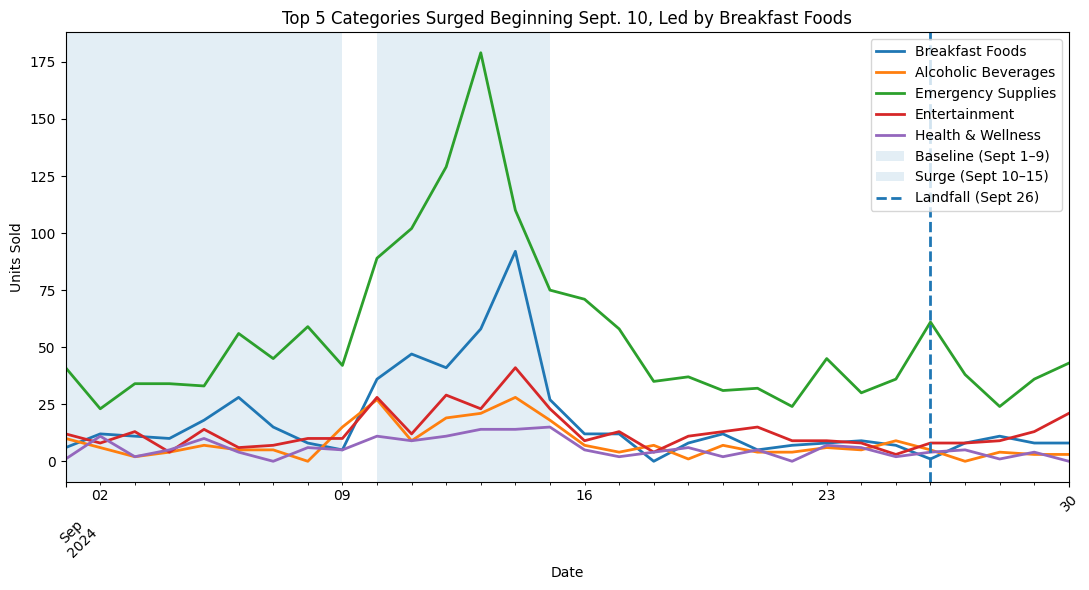

In [14]:
import matplotlib.pyplot as plt

top5 = q1_results.head(5).index.tolist()

ax = daily_q1[top5].plot(figsize=(11, 6), linewidth=2)

ax.axvspan(
    baseline_start,
    baseline_end,
    alpha=0.12,
    label="Baseline (Sept 1–9)"
)

ax.axvspan(
    surge_start,
    surge_end,
    alpha=0.12,
    label="Surge (Sept 10–15)"
)

ax.axvline(
    pd.Timestamp("2024-09-26"),
    linestyle="--",
    linewidth=2,
    label="Landfall (Sept 26)"
)

ax.set_title("Top 5 Categories Surged Beginning Sept. 10, Led by Breakfast Foods")
ax.set_xlabel("Date")
ax.set_ylabel("Units Sold")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Pattern 2 — indexing to baseline so different products are comparable

Water outsells flashlights ten to one, so on a raw chart the flashlight surge is invisible. Divide each series by its own pre-storm average and every product starts at 1.0 — now you are comparing *how much each one moved*, which is the actual question.

In [ ]:
baseline = daily[daily.index < landfall - pd.Timedelta(days=3)].mean()
indexed = daily / baseline

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(indexed.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.set_title('Flashlights spiked hardest relative to normal, at 12x baseline',
             loc='left', fontsize=12)
ax.set_ylabel('multiple of pre-storm average')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(indexed.max().round(1).sort_values(ascending=False))

Two charts, same data, different findings. The raw chart says water is the story; the indexed chart says flashlights are. Both belong in the presentation, in that order.

**TODO:** index your own products to their baseline and see whether your ranking changes.

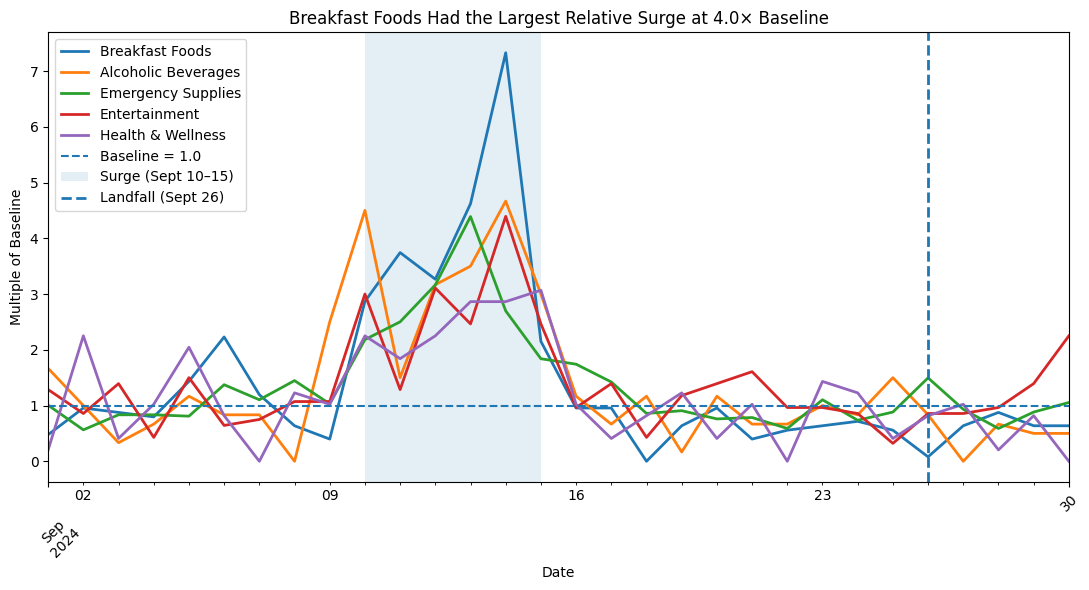

                     surge_multiple  percent_increase
category_clean                                       
Breakfast Foods                4.00            299.56
Alcoholic Beverages            3.39            238.89
Emergency Supplies             2.80            179.56
Entertainment                  2.79            178.57
Health & Wellness              2.52            152.27


In [15]:
top5 = q1_results.head(5).index.tolist()

indexed_q1 = daily_q1[top5].div(baseline_avg[top5])

ax = indexed_q1.plot(figsize=(11, 6), linewidth=2)

ax.axhline(1.0, linestyle="--", linewidth=1.5, label="Baseline = 1.0")

ax.axvspan(
    surge_start,
    surge_end,
    alpha=0.12,
    label="Surge (Sept 10–15)"
)

ax.axvline(
    pd.Timestamp("2024-09-26"),
    linestyle="--",
    linewidth=2,
    label="Landfall (Sept 26)"
)

ax.set_title("Breakfast Foods Had the Largest Relative Surge at 4.0× Baseline")
ax.set_xlabel("Date")
ax.set_ylabel("Multiple of Baseline")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(q1_results[["surge_multiple", "percent_increase"]].head(5).round(2))

### Pattern 3 — before-and-after for Q2

The SKU consolidation question needs a comparison, not a description. Show the number somebody would have reported without your work next to the number with it.

In [ ]:
fragmented = pd.Series({'PT-12': 40, 'SKU#459812': 15, 'POPTART-STRAW': 22})
consolidated = pd.Series({'POPTART-STRAW': 77})

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title('As recorded: three unremarkable SKUs', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title('Consolidated: one product, 77 units', fontsize=10, loc='left')
axes[0].set_ylabel('units')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** build this for your largest consolidated product family. State the multiple.

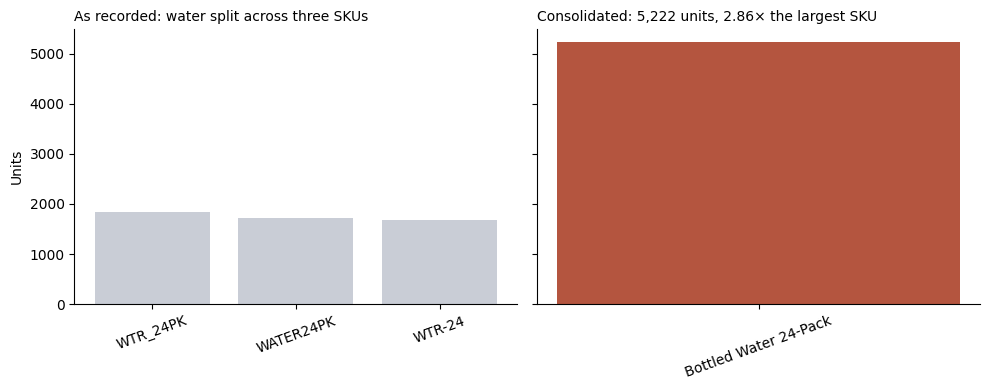

Largest individual SKU: 1829
Consolidated total: 5222
Consolidation multiple: 2.86


In [18]:
fragmented = fragmented_water
consolidated = pd.Series({"Bottled Water 24-Pack": consolidated_water})

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

axes[0].bar(fragmented.index, fragmented.values, color="#c9cdd6")
axes[0].set_title(
    "As recorded: water split across three SKUs",
    fontsize=10,
    loc="left"
)
axes[0].tick_params(axis="x", labelrotation=20)
axes[0].set_ylabel("Units")

axes[1].bar(consolidated.index, consolidated.values, color="#b4553f")
axes[1].set_title(
    "Consolidated: 5,222 units, 2.86× the largest SKU",
    fontsize=10,
    loc="left"
)
axes[1].tick_params(axis="x", labelrotation=20)

for ax in axes:
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

print("Largest individual SKU:", fragmented_water.max())
print("Consolidated total:", consolidated_water)
print(
    "Consolidation multiple:",
    round(consolidated_water / fragmented_water.max(), 2)
)

In [17]:
water_names = [
    "BOTTLED WATER 24PK",
    "Bottled Water 24-Pack",
    "Water - 24 Pack"
]

water = q1[q1["product_name"].isin(water_names)]

fragmented_water = (
    water.groupby("sku")["quantity"]
    .sum()
    .sort_values(ascending=False)
)

consolidated_water = water["quantity"].sum()

print("As recorded:")
print(fragmented_water)
print()
print("Consolidated Bottled Water 24-Pack:", consolidated_water)
print("Multiple vs largest individual SKU:",
      round(consolidated_water / fragmented_water.max(), 2))

As recorded:
sku
WTR_24PK     1829
WATER24PK    1715
WTR-24       1678
Name: quantity, dtype: int64

Consolidated Bottled Water 24-Pack: 5222
Multiple vs largest individual SKU: 2.86


### Pattern 4 — Q4, stores by distance

Aggregate by store, join whatever geography you have, and look for the gradient. Watch the group sizes — a store with four transactions will produce a wild average.

In [ ]:
by_store = pd.DataFrame({
    'store_id': ['FL-105', 'FL-239', 'FL-411', 'FL-502'],
    'surge_multiple': [3.4, 2.9, 1.6, 1.1],
    'miles_from_path': [12, 38, 120, 260],
    'transactions': [4200, 3100, 2800, 90],
})

fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = by_store['transactions'] / 15
ax.scatter(by_store['miles_from_path'], by_store['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in by_store.itertuples():
    ax.annotate(row.store_id, (row.miles_from_path, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Surge falls off with distance from the storm path',
             loc='left', fontsize=12)
ax.set_xlabel('miles from storm path')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('note the smallest bubble: FL-502 has only 90 transactions,')
print('so its 1.1x is barely distinguishable from noise.')

Sizing the points by transaction count is doing real work here — it tells the reader which points to trust. A four-point scatter is not a trend line, and you should say so out loud rather than fitting one.

**TODO:** build your version. If you only have a handful of stores, present it as a table with a comment instead of a scatter — a chart with five points and a regression line will get asked about.

In [ ]:
# TODO

In [20]:
stores = pd.read_csv(
    "ds2002-fa26/notebooks/walmart-hurricane-project/data/store_locations.csv"
)

print(stores.shape)
print(stores.columns.tolist())
stores

(14, 8)
['store_id', 'store_name', 'city', 'state', 'zip_code', 'latitude', 'longitude', 'region']


,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,Florida,34741,28.2920,-81.4076,Central
5,FL-156,Walmart Supercenter Daytona Beach,Daytona Beach,FL,32114,29.2108,-81.0228,East
6,FL-501,Walmart Supercenter Fort Myers,Fort Myers,FL,33901,26.6406,-81.8723,West
7,FL-078,Walmart Supercenter Gainesville,Gainesville,FL,32601,29.6516,-82.3248,North
8,FL-619,Walmart Supercenter Tallahassee,Tallahassee,FL,32301,NaN,NaN,Panhandle
9,FL-445,Walmart Supercenter St. Petersburg,St. Petersburg,Fla.,33701,27.7676,-82.6403,West


In [21]:
!grep -Rni -E "Question 4|Q4|distance|storm path|landfall" \
ds2002-fa26/notebooks/walmart-hurricane-project/README.md \
ds2002-fa26/notebooks/walmart-hurricane-project/data/README.md \
ds2002-fa26/notebooks/walmart-hurricane-project/notebooks/*.ipynb

ds2002-fa26/notebooks/walmart-hurricane-project/notebooks/SaltSquared_2026_10_23_—_Midterm_Checkpoint—_Lab.ipynb:265:              "   avg_daily_shipments  surge_capacity  distance_to_orlando_mi  \\\n",
ds2002-fa26/notebooks/walmart-hurricane-project/notebooks/SaltSquared_2026_10_23_—_Midterm_Checkpoint—_Lab.ipynb:306:              "      <th>distance_to_orlando_mi</th>\n",
ds2002-fa26/notebooks/walmart-hurricane-project/notebooks/SaltSquared_2026_10_23_—_Midterm_Checkpoint—_Lab.ipynb:454:              "summary": "{\n  \"name\": \"distribution\",\n  \"rows\": 5,\n  \"fields\": [\n    {\n      \"column\": \"dc_id\",\n      \"properties\": {\n        \"dtype\": \"string\",\n        \"num_unique_values\": 5,\n        \"samples\": [\n          \"DC-ATL\",\n          \"DC-BHM\",\n          \"DC-DAL\"\n        ],\n        \"semantic_type\": \"\",\n        \"description\": \"\"\n      }\n    },\n    {\n      \"column\": \"dc_name\",\n      \"properties\": {\n        \"dtype\": \"string\",\n  

### Before you leave

- At least two presentation-ready charts, each with a message title
- Q1 has a stated baseline window and a multiple
- Q2 has a before-and-after comparison
- Everything pushed

Monday is presentations. The timing breakdown and the self-check are in Monday's notebook — read it tonight, not Monday morning.

---

## Checkpoint (participation)

Report the surge multiple you found for your top product and the baseline window you used to get it.

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Thursday 11:59pm ET**. One submission per person, not per group.

In [22]:
top_product = "Breakfast Foods"
surge_multiple = 4.00
baseline_window = "Sept 1–9, 2024"
charts_ready = 3

print("top product:", top_product)
print("surge multiple:", surge_multiple)
print("baseline window:", baseline_window)
print("charts ready:", charts_ready)

top product: Breakfast Foods
surge multiple: 4.0
baseline window: Sept 1–9, 2024
charts ready: 3
